# Fixing the STL-10 binary CNN (cat vs dog)

In the original runs, the binary CNN on STL-10 barely learned: training accuracy stayed near 50-60% and the adversarially trained version was stuck at chance.

Likely reason: the binary training set has only 1,000 images. With batch size 128, one epoch is only 8 gradient steps, so 30 epochs are 240 steps in total.

Here we compare a few training setups on a **validation split** (taken from the training set), so the test set is only used once, for the final model.

In [1]:
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, random_split

from advrobust.utils import SEED, device, set_seed
from advrobust.data import load_stl10
from advrobust.models import BinaryCNNSTL10, BinaryCNNSTL10BN
from advrobust.train import train
from advrobust.evaluate import evaluate_clean, evaluate_fgsm
from advrobust.augment import random_flip

print("Using device:", device)

Using device: mps


In [2]:
stl = load_stl10()

train_full = stl["stl_train_bin_img"]   # 1000 images
test_loader = stl["stl_test_loader_bin_img"]

# 850 train / 150 validation
n_val = 150
train_sub, val_sub = random_split(
    train_full,
    [len(train_full) - n_val, n_val],
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = DataLoader(val_sub, batch_size=128, shuffle=False)

def make_loader(ds, batch_size):
    return DataLoader(ds, batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(SEED))

print(len(train_sub), "train /", len(val_sub), "validation")

850 train / 150 validation


## 1. Compare training setups

Each setup changes one thing compared to the previous one:

| Name | Model | Optimizer | Batch size | Augmentation |
|---|---|---|---|---|
| A: original | CNN | SGD, lr=0.01 | 128 | no |
| B: adam | CNN | Adam, lr=1e-3 | 128 | no |
| C: small batch | CNN | Adam, lr=1e-3 | 32 | no |
| D: batchnorm | CNN + BatchNorm | Adam, lr=1e-3 | 32 | no |
| E: flip | CNN + BatchNorm | Adam, lr=1e-3 | 32 | random flip |

In [3]:
EPOCHS = 40

setups = {
    "A: original":    dict(model_cls=BinaryCNNSTL10,   batch_size=128, lr=0.01, optimizer="sgd",  augment=None),
    "B: adam":        dict(model_cls=BinaryCNNSTL10,   batch_size=128, lr=1e-3, optimizer="adam", augment=None),
    "C: small batch": dict(model_cls=BinaryCNNSTL10,   batch_size=32,  lr=1e-3, optimizer="adam", augment=None),
    "D: batchnorm":   dict(model_cls=BinaryCNNSTL10BN, batch_size=32,  lr=1e-3, optimizer="adam", augment=None),
    "E: flip":        dict(model_cls=BinaryCNNSTL10BN, batch_size=32,  lr=1e-3, optimizer="adam", augment=random_flip),
}

val_results = {}

for name, s in setups.items():
    print("Training", name)
    set_seed()
    model = train(
        s["model_cls"](),
        make_loader(train_sub, s["batch_size"]),
        binary=True,
        epochs=EPOCHS,
        lr=s["lr"],
        optimizer=s["optimizer"],
        augment=s["augment"],
    )
    val_results[name] = evaluate_clean(model, val_loader, binary=True)
    print("validation accuracy:", round(val_results[name], 4))
    print("")

Training A: original
epoch 1 | loss: 0.693 | train acc: 0.5094
epoch 5 | loss: 0.6919 | train acc: 0.5247
epoch 10 | loss: 0.6885 | train acc: 0.5471
epoch 15 | loss: 0.6822 | train acc: 0.5753
epoch 20 | loss: 0.679 | train acc: 0.5694
epoch 25 | loss: 0.6642 | train acc: 0.5941
epoch 30 | loss: 0.6622 | train acc: 0.5847
epoch 35 | loss: 0.6218 | train acc: 0.6224
epoch 40 | loss: 0.5531 | train acc: 0.7224
validation accuracy: 0.68

Training B: adam
epoch 1 | loss: 0.7267 | train acc: 0.5047
epoch 5 | loss: 0.6842 | train acc: 0.5659
epoch 10 | loss: 0.5774 | train acc: 0.6859
epoch 15 | loss: 0.4487 | train acc: 0.78
epoch 20 | loss: 0.2668 | train acc: 0.8765
epoch 25 | loss: 0.1104 | train acc: 0.9659
epoch 30 | loss: 0.028 | train acc: 0.9953
epoch 35 | loss: 0.0043 | train acc: 1.0
epoch 40 | loss: 0.0014 | train acc: 1.0
validation accuracy: 0.6067

Training C: small batch
epoch 1 | loss: 0.7038 | train acc: 0.5035
epoch 5 | loss: 0.629 | train acc: 0.6341
epoch 10 | loss: 0.4

A: original : 0.68
B: adam : 0.607
C: small batch : 0.6
D: batchnorm : 0.72
E: flip : 0.653


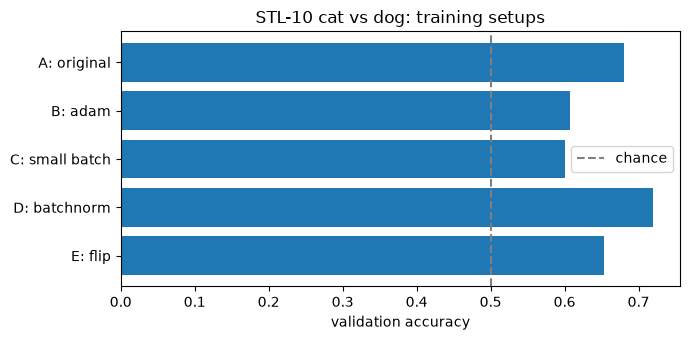

In [4]:
for name, acc in val_results.items():
    print(name, ":", round(acc, 3))

plt.figure(figsize=(7, 3.5))
plt.barh(list(val_results.keys()), list(val_results.values()))
plt.axvline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("validation accuracy")
plt.title("STL-10 cat vs dog: training setups")
plt.legend()
plt.gca().invert_yaxis()
plt.tight_layout()

## 2. Final model

Pick the best setup from above (by validation accuracy), retrain it on all 1,000 training images, and evaluate it on the test set once.

In [5]:
BEST = max(val_results, key=val_results.get)   # or set it by hand
best = setups[BEST]
print("Best setup:", BEST)

set_seed()
stl_cnn_bin = train(
    best["model_cls"](),
    make_loader(train_full, best["batch_size"]),
    binary=True,
    epochs=EPOCHS,
    lr=best["lr"],
    optimizer=best["optimizer"],
    augment=best["augment"],
)
test_acc = evaluate_clean(stl_cnn_bin, test_loader, binary=True)
print("Test accuracy:", round(test_acc, 4))

Best setup: D: batchnorm
epoch 1 | loss: 1.4325 | train acc: 0.514
epoch 5 | loss: 0.6055 | train acc: 0.686
epoch 10 | loss: 0.4113 | train acc: 0.818
epoch 15 | loss: 0.1698 | train acc: 0.935
epoch 20 | loss: 0.0643 | train acc: 0.981
epoch 25 | loss: 0.0498 | train acc: 0.984
epoch 30 | loss: 0.1103 | train acc: 0.953
epoch 35 | loss: 0.0053 | train acc: 0.999
epoch 40 | loss: 0.0006 | train acc: 1.0
Test accuracy: 0.725


## 3. FGSM and adversarial training with the new setup

Same epsilons and adversarial training settings as in the main notebook (epsilon=0.015, adv_weight=0.5).

In [6]:
EPSILONS_STL = [0.0, 0.002, 0.005, 0.01, 0.015, 0.02, 0.025]

print("Training FGSM adversarial CNN:")
set_seed()
stl_cnn_bin_adv = train(
    best["model_cls"](),
    make_loader(train_full, best["batch_size"]),
    binary=True,
    epochs=EPOCHS,
    lr=best["lr"],
    optimizer=best["optimizer"],
    augment=best["augment"],
    adv_epsilon=0.015,
    adv_weight=0.5,
)
print("Clean test accuracy (adversarial training):", round(evaluate_clean(stl_cnn_bin_adv, test_loader, binary=True), 4))

results = {"standard": [], "adversarial training": []}
for eps in EPSILONS_STL:
    for name, m in [("standard", stl_cnn_bin), ("adversarial training", stl_cnn_bin_adv)]:
        if eps == 0.0:
            acc = evaluate_clean(m, test_loader, binary=True)
        else:
            acc = evaluate_fgsm(m, test_loader, eps, binary=True)
        results[name].append(acc)

print("epsilon:", *EPSILONS_STL)
for name, accs in results.items():
    print(name, ":", *[round(a, 3) for a in accs])

Training FGSM adversarial CNN:
epoch 1 | loss: 1.4179 | train acc: 0.514
epoch 5 | loss: 0.6963 | train acc: 0.616
epoch 10 | loss: 0.6206 | train acc: 0.734
epoch 15 | loss: 0.554 | train acc: 0.795
epoch 20 | loss: 0.4482 | train acc: 0.883
epoch 25 | loss: 0.3325 | train acc: 0.926
epoch 30 | loss: 0.1315 | train acc: 0.991
epoch 35 | loss: 0.0623 | train acc: 0.998
epoch 40 | loss: 0.0651 | train acc: 0.998
Clean test accuracy (adversarial training): 0.7013
epsilon: 0.0 0.002 0.005 0.01 0.015 0.02 0.025
standard : 0.725 0.644 0.49 0.29 0.158 0.083 0.039
adversarial training : 0.701 0.669 0.626 0.535 0.45 0.371 0.302


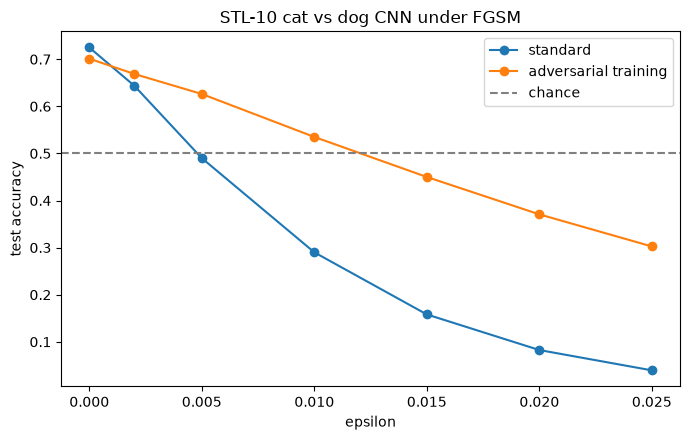

In [7]:
plt.figure(figsize=(7, 4.5))
for name, accs in results.items():
    plt.plot(EPSILONS_STL, accs, marker="o", label=name)
plt.axhline(0.5, color="gray", linestyle="--", label="chance")
plt.xlabel("epsilon")
plt.ylabel("test accuracy")
plt.title("STL-10 cat vs dog CNN under FGSM")
plt.legend()
plt.tight_layout()